# RFM 客户细分与聚类画像

**业务问题：** 如何用消费最近度、频次和金额形成可解释分层，并对照聚类画像？

> 本项目使用仓库内的合成教学数据，不代表真实企业业绩。笔记本复用同目录分析模块，确保脚本、结果表与图表口径一致。请使用 Python 3.11 并从仓库内部启动 Jupyter。

## 1. 读取数据

根据当前目录向上定位仓库，不在 notebook 中依赖 `__file__`，也不硬编码电脑路径。

In [1]:
from pathlib import Path
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from io import BytesIO

# Works when Jupyter starts at the repo root, project directory or notebook directory.
start = Path.cwd().resolve()
root = next((p for p in (start, *start.parents)
             if (p / 'projects' / 'customer-segmentation' / 'scripts' / 'analyze.py').is_file()), None)
if root is None:
    raise FileNotFoundError('请在本仓库内启动 Jupyter，或先切换到仓库根目录。')
project_dir = root / 'projects' / 'customer-segmentation'
module_path = project_dir / 'scripts' / 'analyze.py'
spec = importlib.util.spec_from_file_location('customer_segmentation', module_path)
analysis = importlib.util.module_from_spec(spec)
spec.loader.exec_module(analysis)
df = analysis.load_data()
assert not df.empty
print('Input rows:', len(df))
display(df.head())


Input rows: 20


,customer_id,recency_days,frequency,monetary,age,gender,city
0,C001,12,8,45000,32,F,Beijing
1,C002,45,3,12000,28,M,Shanghai
2,C003,8,12,68000,35,F,Guangzhou
3,C004,120,1,2500,24,M,Shenzhen
4,C005,30,5,18000,29,F,Beijing


## 2. 数据质量检查

报告缺失与整行重复。重复事件可能是真实行为，不应未经业务判断直接删除。分析模块进一步校验必要字段和数值范围。

In [2]:
display(df.isna().sum().to_frame('missing_count'))
print('Exact duplicate rows:', int(df.duplicated().sum()))

,missing_count
customer_id,0
recency_days,0
frequency,0
monetary,0
age,0
gender,0
city,0


Exact duplicate rows: 0


## 3. 指标定义与独立复算

R 越小越好，F/M 越大越好。RFM 分数和业务规则分层与 K-Means 聚类是两种不同方法；重复值应同分，不能为了凑等人数强行拆开。聚类前标准化，固定随机种子，k=4 是演示选择而非已经验证的最优值。

In [3]:
rfm_columns = ['recency_days', 'frequency', 'monetary']
display(df[rfm_columns].describe().round(2))
print('Customers:', df['customer_id'].nunique())
print('Observed monetary total:', df['monetary'].sum())

,recency_days,frequency,monetary
count,20.00,20.00,20.00
mean,62.55,6.05,29840.00
std,77.29,5.27,32205.12
min,5.00,1.00,1500.00
25%,13.50,2.00,5750.00
50%,27.50,4.50,16500.00
75%,82.50,8.25,45750.00
max,300.00,20.00,120000.00


Customers: 20
Observed monetary total: 596800


## 4. 完整分析结果

下面调用可复用的 `analyze(df)`，展示结果表；业务口径详见相邻项目说明和脚本。

In [4]:
results = analysis.analyze(df)
assert isinstance(results, dict) and results
for name, table in results.items():
    print(f'--- {name} ---')
    with pd.option_context('display.max_rows', 50, 'display.max_columns', 20):
        display(table)

--- overview ---


,customers,observed_monetary_total,observed_rule_groups,example_cluster_count
0,20,596800,3,4


--- rfm_segments ---


,segment,count,avg_recency,avg_frequency,avg_monetary,total_monetary,customer_share_pct,monetary_share_pct
0,Champions,8,11.125000,11.250000,61375.000000,491000,40.0,82.272118
1,Loyal,3,25.666667,5.000000,18333.333333,55000,15.0,9.215818
2,Others,9,120.555556,1.777778,5644.444444,50800,45.0,8.512064


--- kmeans_clusters ---


,cluster,count,avg_recency,avg_frequency,avg_monetary
0,0,2,6.000000,17.500000,102500.000000
1,1,7,14.142857,8.714286,44000.000000
2,2,9,71.111111,2.555556,8944.444444
3,3,2,250.000000,1.000000,1650.000000


--- customer_segments ---


,customer_id,recency_days,frequency,monetary,age,gender,city,r_score,f_score,m_score,rfm_score,segment,cluster
0,C001,12,8,45000,32,F,Beijing,4,4,4,444,Champions,1
1,C002,45,3,12000,28,M,Shanghai,2,2,3,223,Others,2
2,C003,8,12,68000,35,F,Guangzhou,5,5,5,555,Champions,1
3,C004,120,1,2500,24,M,Shenzhen,1,1,1,111,Others,2
4,C005,30,5,18000,29,F,Beijing,3,3,3,333,Loyal,2
5,C006,5,20,120000,40,M,Shanghai,5,5,5,555,Champions,0
6,C007,90,2,6000,31,F,Guangzhou,2,2,2,222,Others,2
7,C008,18,7,32000,27,M,Shenzhen,4,4,4,444,Champions,1
8,C009,25,4,15000,33,F,Beijing,3,3,3,333,Loyal,2
9,C010,200,1,1800,22,M,Shanghai,1,1,1,111,Others,3


--- kmeans_inertia ---


,k,inertia
0,2,26.646452
1,3,14.696743
2,4,7.797916
3,5,4.874940
4,6,3.107797
5,7,2.029538


## 5. 可视化

图表与脚本使用同一结果字典，不另写一套计算逻辑。

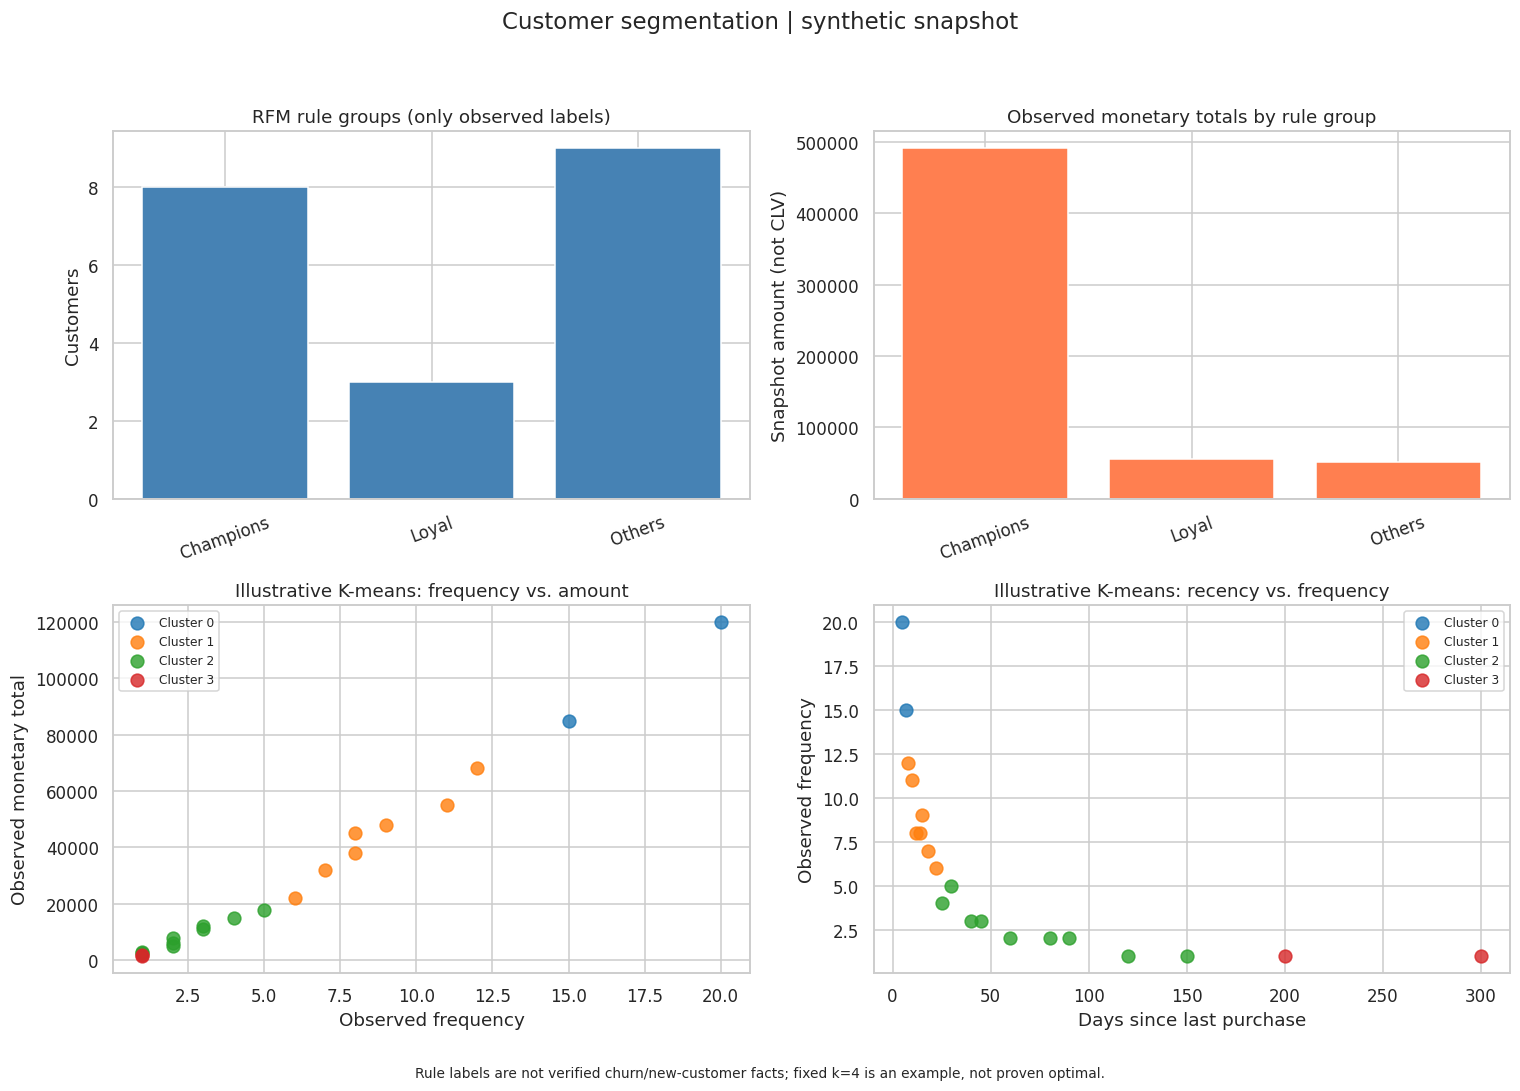

In [5]:
fig = analysis.plot_dashboard(results)
# Explicit PNG display also works with the headless Agg backend.
image = BytesIO()
fig.savefig(image, format='png', dpi=110, bbox_inches='tight')
display(Image(data=image.getvalue()))
plt.close(fig)

## 6. 结论、建议与边界

这 20 位合成客户只用于演示分析流程，规则可能使某些分组为空，不应预先承诺每组占比。Champions 等名称是业务标签，不是已验证的真实用户类型。现有数据没有未来价值目标或流失标签，因此没有完成 CLV 预测或流失预测。建议用真实订单计算窗口化 RFM，并用后续实验衡量分层运营收益。

**复现检查：** 从首个代码单元开始运行全部单元；仓库统一验证命令为 `python scripts/validate_portfolio.py`。生成笔记本和实际执行笔记本是两个不同步骤，执行结果以验证报告为准。